In [19]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

train_df = pd.read_csv('data/train.csv', index_col=[0])
test_df = pd.read_csv('data/test.csv', index_col=[0])

## treino

In [20]:
train_df.head()

,pelvic_incidence,pelvic_tilt,lumbar_lordosis_angle,sacral_slope,pelvic_radius,degree_spondylolisthesis,class
0,39.056951,10.060991,25.015378,28.995960,114.405425,4.564259,Hernia
1,68.832021,22.218482,50.092194,46.613539,105.985135,-3.530317,Hernia
2,49.712859,9.652075,28.317406,40.060784,108.168725,7.918501,Hernia
3,40.250200,13.921907,25.124950,26.328293,130.327871,2.230652,Hernia
4,53.432928,15.864336,37.165934,37.568592,120.567523,5.988551,Hernia


In [21]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 217 entries, 0 to 216
Data columns (total 7 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   pelvic_incidence          217 non-null    float64
 1   pelvic_tilt               217 non-null    float64
 2   lumbar_lordosis_angle     217 non-null    float64
 3   sacral_slope              217 non-null    float64
 4   pelvic_radius             217 non-null    float64
 5   degree_spondylolisthesis  217 non-null    float64
 6   class                     217 non-null    str    
dtypes: float64(6), str(1)
memory usage: 12.0 KB


In [22]:
train_df.describe()

,pelvic_incidence,pelvic_tilt,lumbar_lordosis_angle,sacral_slope,pelvic_radius,degree_spondylolisthesis
count,217.000000,217.000000,217.000000,217.000000,217.000000,217.000000
mean,60.458343,17.541355,52.660081,42.916988,118.073520,27.715448
std,18.045677,10.786425,19.226267,13.631236,13.920744,40.965137
min,26.147921,-6.554948,14.000000,13.516568,70.082575,-11.058179
25%,46.236399,9.976664,36.329137,33.366366,110.660701,1.517203
50%,57.145851,16.417462,51.000000,42.447102,118.151531,13.683047
75%,74.469082,22.432950,63.232302,51.766175,126.398188,49.159426
max,129.834041,49.431864,125.742385,121.429566,163.071041,418.543082


contagem de classes

In [23]:
train_df.iloc[:,-1].value_counts()

class
Spondylolisthesis    105
Normal                70
Hernia                42
Name: count, dtype: int64

ta desbalanceado. fato que precisa de estratificação

In [24]:
class_column = train_df.columns[-1]
features = train_df.columns[:-1]
print(class_column)
print(features)

class
Index(['pelvic_incidence', 'pelvic_tilt', 'lumbar_lordosis_angle',
       'sacral_slope', 'pelvic_radius', 'degree_spondylolisthesis'],
      dtype='str')


"A Kernel Density Estimation (KDE) plot is a type of plot that visualizes the estimated probability density function of a continuous variable. Unlike a histogram, which displays data using discrete bars grouped into intervals, a KDE plot represents the distribution as a smooth, continuous curve based on all data points." https://codefinity.com/courses/v2/61928667-6699-4af9-a146-b70e73fce3c5/d6354309-3168-44c6-b630-26cf849bd32f/f2dcae95-a3e5-4751-8730-870f0050101b

Eu tenho claramente variaveis numericas e continuas (pode asusmir inf valores dentro de um intervalo)

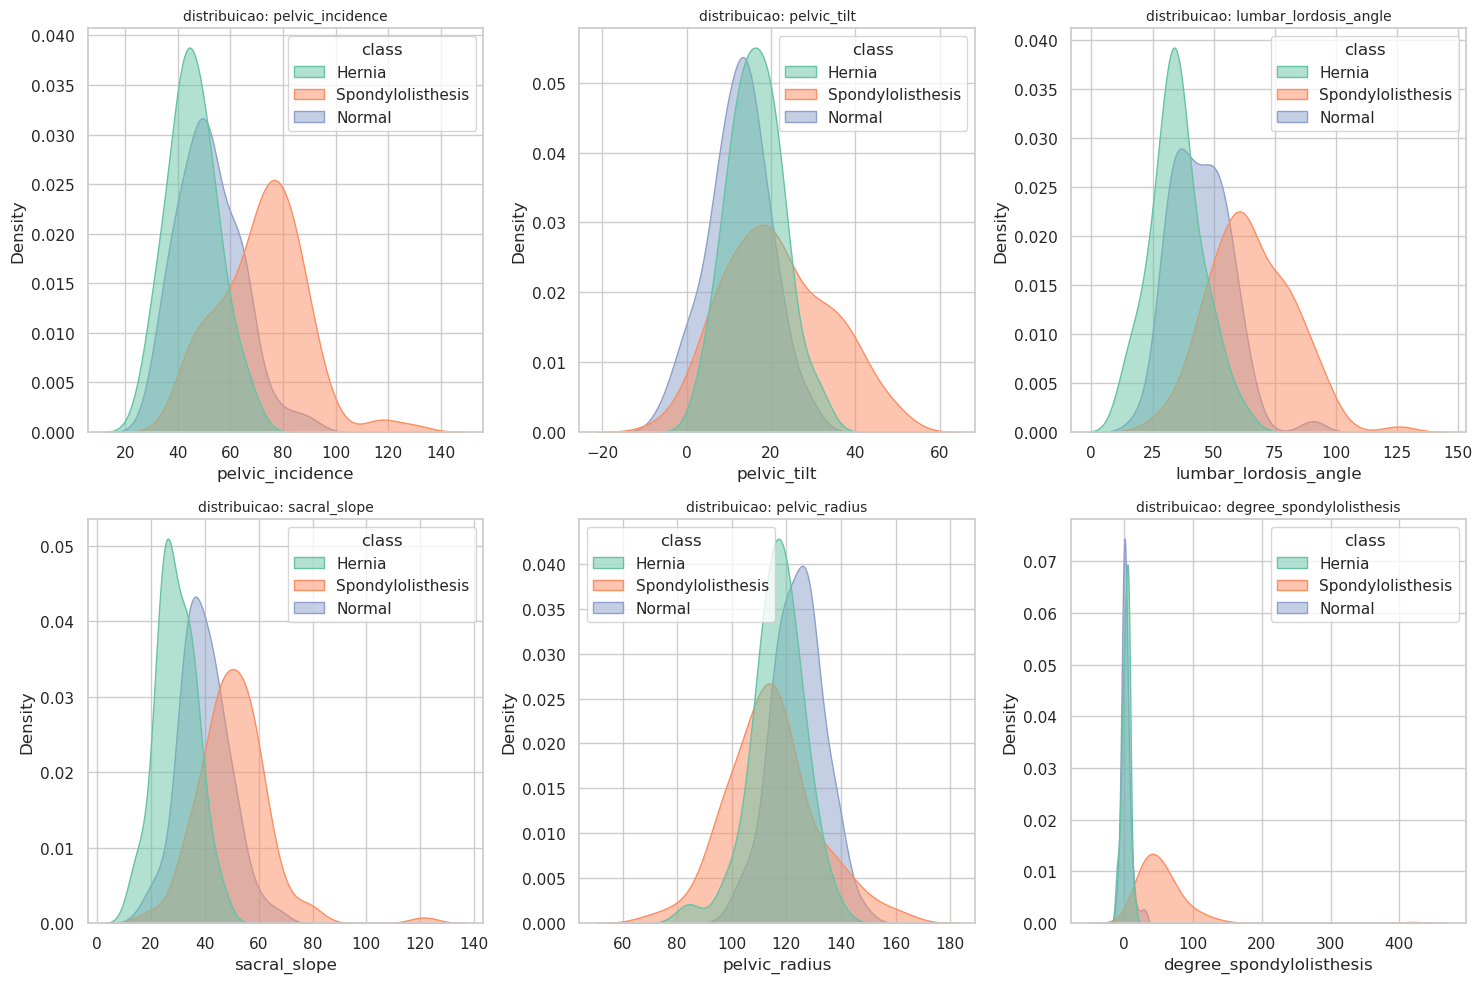

In [25]:
sns.set_theme(style='whitegrid')

plt.figure(figsize=(15, 10))
for i, col in enumerate(features):
    plt.subplot(2, 3, i+1)
    sns.kdeplot(data=train_df, x=col, hue=class_column, fill=True, common_norm=False, palette='Set2', alpha=0.5)
    plt.title(f"distribuicao: {col}", fontsize=10)
plt.tight_layout()
plt.show()

# matrix de correlacao

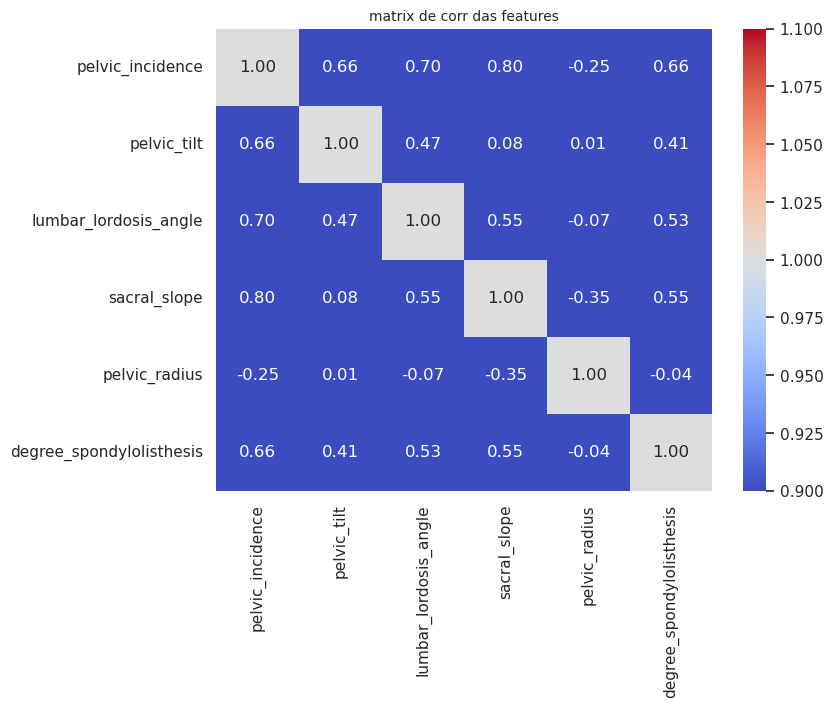

In [ ]:
plt.figure(figsize=(8, 6))
corr = train_df[features].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title("matrix de corr das features", fontsize=10)
plt.show()